# JDsearch – Step A1: efficient loading

Streams the two raw files once, never holding them fully in RAM, and writes compact Parquet tables:

| Table | One row per | Key columns |
|---|---|---|
| `tests` | user (= test query) | `user_id` (line index in file), `query`, `n_cand`, `n_pos`, `n_hist`, per-type event counts, `span_s` |
| `events` | history event | `user_id`, `pos`, `wid`, `etype` (1 click, 2 cart, 3 order, 4 follow), `qless`, `gap_prev_s`, **`secs_before_q`** |
| `events_qry` | history event | raw query term-ids of the event (row-aligned with `events`) |
| `cands` | candidate | `user_id`, `cand_pos`, `wid`, `label` (0 none, 1 click, 2 cart, 3 order) |
| `products` | product | `wid`, `name`, `brand_id`, `brand_name`, `cate_id_1..4`, `shop_id` |

`secs_before_q` = seconds between the event and the test query (the reverse cumulative sum of the interval list), which is exactly what the temporal trace in step A4 needs.

## 1. Setup and locate the raw files

In [ ]:
import os, glob, shutil, time
import numpy as np, pandas as pd
import pyarrow as pa, pyarrow.csv as pacsv, pyarrow.compute as pc, pyarrow.parquet as pq

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE  = '/content/drive/MyDrive/bt4222_project'
    LOCAL = '/content/jd_local'
except ImportError:
    BASE, LOCAL = os.environ['JD_BASE'], os.environ['JD_LOCAL']

OUT = f'{BASE}/Data/Processed'
os.makedirs(OUT, exist_ok=True); os.makedirs(LOCAL, exist_ok=True)

def find(name):
    hits = glob.glob(f'{BASE}/**/{name}', recursive=True)
    if not hits: raise FileNotFoundError(f'{name} not found under {BASE}')
    return hits[0]

RAW_UB, RAW_PM = find('user_behavior_data.txt'), find('product_meta_data.txt')
for p in (RAW_UB, RAW_PM): print(f'{os.path.getsize(p)/1e9:7.2f} GB  {p}')

Mounted at /content/drive
   0.96 GB  /content/drive/MyDrive/bt4222_project/Data/user_behavior_data.txt
   4.84 GB  /content/drive/MyDrive/bt4222_project/Data/product_meta_data.txt


In [ ]:
# Sanity-check the raw layout on the first line of each file (^X = term-id separator)
show = lambda x, n: x.replace('\x18', '^X')[:n] + ('...' if len(x) > n else '')
with open(RAW_UB, 'rb') as f: ub = f.readline().decode().rstrip('\r\n').split('\t')
with open(RAW_PM, 'rb') as f: pm = f.readline().decode().rstrip('\r\n').split('\t')
print(len(ub), 'fields in user_behavior (expect 7):', [show(x, 40) for x in ub])
print(len(pm), 'fields in product_meta  (expect 13):', [show(x, 25) for x in pm])

7 fields in user_behavior (expect 7): ['query', 'candidate_wid_list', 'candidate_label_list', 'history_qry_list', 'history_wid_list', 'history_type_list', 'history_time_list']
13 fields in product_meta  (expect 13): ['wid', 'name', 'brand_id', 'brand_name', 'cate_id_1', 'cate_name_1', 'cate_id_2', 'cate_name_2', 'cate_id_3', 'cate_name_3', 'cate_id_4', 'cate_name_4', 'shop_id']


## 2. Converters (streaming, low RAM)

In [ ]:
PM_COLS = ['wid', 'name', 'brand_id', 'brand_name', 'cate_id_1', 'cate_name_1', 'cate_id_2', 'cate_name_2',
           'cate_id_3', 'cate_name_3', 'cate_id_4', 'cate_name_4', 'shop_id']

def convert_products(src, dst, keep_cate_names=False):
    """Stream product_meta_data.txt -> Parquet with pyarrow's multithreaded CSV reader (low RAM)."""
    is_text = lambda c: c in ('name', 'brand_name') or c.startswith('cate_name')
    skipped = [0]
    def bad_row(row): skipped[0] += 1; return 'skip'
    with open(src, 'rb') as f: has_header = f.readline().split(b'\t')[0] == b'wid'
    ro = pacsv.ReadOptions(column_names=PM_COLS, block_size=64 << 20, skip_rows=int(has_header))
    po = pacsv.ParseOptions(delimiter='\t', quote_char=False, invalid_row_handler=bad_row)
    co = pacsv.ConvertOptions(column_types={c: pa.string() if is_text(c) else pa.int64() for c in PM_COLS},
                              null_values=[''], strings_can_be_null=True,
                              include_columns=[c for c in PM_COLS if keep_cate_names or not c.startswith('cate_name')])
    writer, n = None, 0
    with pacsv.open_csv(src, read_options=ro, parse_options=po, convert_options=co) as rd:
        for batch in rd:
            t = pa.Table.from_batches([batch])
            if writer is None: writer = pq.ParquetWriter(dst, t.schema, compression='zstd')
            writer.write_table(t); n += t.num_rows
    writer.close()
    print(f'products: {n:,} rows, {skipped[0]} malformed rows skipped')

In [ ]:
ETYPE = {'CLICK': 1, 'CART': 2, 'ORD': 3, 'FLW': 4}     # 1-3 share the scale of the candidate labels

EV  = pa.schema([('user_id', pa.int32()), ('pos', pa.int32()), ('wid', pa.int64()), ('etype', pa.int8()),
                 ('qless', pa.bool_()), ('gap_prev_s', pa.int32()), ('secs_before_q', pa.int32())])
EVQ = pa.schema([('user_id', pa.int32()), ('pos', pa.int32()), ('qry', pa.string())])
CA  = pa.schema([('user_id', pa.int32()), ('cand_pos', pa.int16()), ('wid', pa.int64()), ('label', pa.int8())])
TE  = pa.schema([('user_id', pa.int32()), ('query', pa.string()), ('n_cand', pa.int16()), ('n_pos', pa.int16()),
                 ('n_hist', pa.int32()), ('last_gap_s', pa.int32()), ('span_s', pa.int64()),
                 ('n_click', pa.int32()), ('n_cart', pa.int32()), ('n_ord', pa.int32()),
                 ('n_flw', pa.int32()), ('n_qless', pa.int32())])

lst = lambda s: s.split('_') if s else []
arr = lambda s, dt: np.array(s.split('_'), dtype=dt) if s else np.empty(0, dt)

def convert_behavior(src, out_dir, chunk_users=5000):
    """Stream user_behavior_data.txt line by line -> events / events_qry / cands / tests Parquet files.
    Line: query \t cand_wids \t cand_labels \t hist_qrys \t hist_wids \t hist_types \t hist_times (lists joined by '_')."""
    names, schemas = ['events', 'events_qry', 'cands', 'tests'], [EV, EVQ, CA, TE]
    wr = {k: pq.ParquetWriter(f'{out_dir}/{k}.parquet', s, compression='zstd') for k, s in zip(names, schemas)}
    ev, qs, ca, te = [], [], [], []
    stat = dict(users=0, bad_lines=0, unknown_types=0, events=0, cands=0)
    size, done, t0, nflush = os.path.getsize(src), 0, time.time(), 0

    def flush():
        nonlocal nflush
        if te:
            u, p, w, t, ql, g, sb = (np.concatenate(x) for x in zip(*ev)) if ev else [np.empty(0)] * 7
            wr['events'].write_table(pa.table(dict(user_id=u, pos=p, wid=w, etype=t, qless=ql,
                                                   gap_prev_s=g, secs_before_q=sb), schema=EV))
            wr['events_qry'].write_table(pa.table(dict(user_id=u, pos=p, qry=pa.array(qs, pa.string())), schema=EVQ))
            cu, cp, cw, cl = (np.concatenate(x) for x in zip(*ca))
            wr['cands'].write_table(pa.table(dict(user_id=cu, cand_pos=cp, wid=cw, label=cl), schema=CA))
            wr['tests'].write_table(pa.table(dict(zip(TE.names, zip(*te))), schema=TE))
            ev.clear(); qs.clear(); ca.clear(); te.clear(); nflush += 1
            if nflush % 10 == 0:
                print(f'  {done/size:6.1%}  {stat["users"]:,} users  {time.time()-t0:5.0f}s')

    with open(src, 'rb', buffering=16 << 20) as f:
        for uid, raw in enumerate(f):
            done += len(raw)
            fl = raw.decode('utf-8', 'replace').rstrip('\r\n').split('\t')
            try:
                if len(fl) != 7: raise ValueError
                q, cw, cl, hq, hw, ht, hg = fl
                cw, cl = arr(cw, np.int64), arr(cl, np.float64).astype(np.int8)
                wid, hq, ht = arr(hw, np.int64), lst(hq), lst(ht)
                gaps = arr(hg, np.int64)                       # n_hist + 1 entries, gaps[0] = 0
                n = len(wid)
                if not (len(cw) == len(cl) and len(hq) == len(ht) == n and len(gaps) == n + 1): raise ValueError
            except ValueError:
                stat['bad_lines'] += 1; continue
            et = np.fromiter((ETYPE.get(x, 0) for x in ht), np.int8, count=n)
            stat['unknown_types'] += int((et == 0).sum())
            rc = np.cumsum(gaps[::-1])[::-1]                   # rc[k] = sum(gaps[k:])
            ql = np.fromiter((x == '-1' for x in hq), bool, count=n)
            if n:
                ev.append((np.full(n, uid, np.int32), np.arange(n, dtype=np.int32), wid, et, ql, gaps[:-1], rc[1:]))
                qs.extend(None if x == '-1' else x for x in hq)
            ca.append((np.full(len(cw), uid, np.int32), np.arange(len(cw), dtype=np.int16), cw, cl))
            bc = np.bincount(et, minlength=5)
            te.append((uid, q, len(cw), int((cl > 0).sum()), n, int(gaps[-1]), int(rc[0]),
                       int(bc[1]), int(bc[2]), int(bc[3]), int(bc[4]), int(ql.sum())))
            stat['users'] += 1; stat['events'] += n; stat['cands'] += len(cw)
            if len(te) >= chunk_users: flush()
    flush()
    for w in wr.values(): w.close()
    print('behavior:', {k: f'{v:,}' for k, v in stat.items()}, f'| {time.time()-t0:.0f}s')

## 3. Run once (skipped automatically if the Parquet files already exist on Drive)

In [ ]:
NAMES = ['events', 'events_qry', 'cands', 'tests', 'products']

for n in NAMES:
    p = f'{OUT}/{n}.parquet'
    print(f'{n:12s}', f'{os.path.getsize(p)/1e6:9.1f} MB' if os.path.exists(p) else 'MISSING')
print(OUT)

events       MISSING
events_qry   MISSING
cands        MISSING
tests        MISSING
products     MISSING
/content/drive/MyDrive/bt4222_project/Data/Processed


In [ ]:
NAMES = ['events', 'events_qry', 'cands', 'tests', 'products']

def to_local(src):
    dst = f'{LOCAL}/{os.path.basename(src)}'
    if not (os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(src)):
        t = time.time(); shutil.copyfile(src, dst); print(f'copied {os.path.basename(src)} to local disk in {time.time()-t:.0f}s')
    return dst

def ensure_processed(force=False):
    """Parse once; later sessions just copy the finished Parquet files back from Drive."""
    if not force and all(os.path.exists(f'{OUT}/{n}.parquet') for n in NAMES):
        for n in NAMES:
            if not os.path.exists(f'{LOCAL}/{n}.parquet'): shutil.copyfile(f'{OUT}/{n}.parquet', f'{LOCAL}/{n}.parquet')
        print('Parquet files found on Drive, nothing to parse'); return
    pm, ub = to_local(RAW_PM), to_local(RAW_UB)
    convert_products(pm, f'{LOCAL}/products.parquet')
    convert_behavior(ub, LOCAL)
    for n in NAMES: shutil.copyfile(f'{LOCAL}/{n}.parquet', f'{OUT}/{n}.parquet')
    print('Parquet files saved to', OUT)

ensure_processed()

copied product_meta_data.txt to local disk in 122s
copied user_behavior_data.txt to local disk in 19s
products: 12,141,247 rows, 0 malformed rows skipped
   28.8%  50,000 users     26s
   57.4%  100,000 users     49s
   86.3%  150,000 users     72s
behavior: {'users': '173,831', 'bad_lines': '1', 'unknown_types': '0', 'events': '26,667,260', 'cands': '15,510,012'} | 82s
Parquet files saved to /content/drive/MyDrive/bt4222_project/Data/Processed


## 4. Load back and sanity-check

In [ ]:
def load(name, columns=None):
    """Read one table into pandas with int64 columns downcast to the smallest integer type."""
    df = pq.read_table(f'{LOCAL}/{name}.parquet', columns=columns).to_pandas()
    for c in df.select_dtypes('int64').columns: df[c] = pd.to_numeric(df[c], downcast='integer')
    return df

tests = load('tests')
print(f'{len(tests):,} users / test queries | {tests.n_hist.sum():,} history events | {tests.n_cand.sum():,} candidate rows')
print(f'users with empty history: {(tests.n_hist == 0).mean():.1%} | test queries with a positive label: {(tests.n_pos > 0).mean():.1%}')
print('history length quantiles:', tests.n_hist.quantile([.5, .9, .99, 1]).astype(int).to_dict())
tot = tests[['n_click', 'n_cart', 'n_ord', 'n_flw']].sum()
print('event-type share:', (tot / tot.sum()).round(4).to_dict(), '| query-less share:', round(tests.n_qless.sum() / tests.n_hist.sum(), 4))
print(f'history span (days): median {tests.span_s.median()/86400:.1f}, max {tests.span_s.max()/86400:.1f}')

# share of history events whose product has metadata
ev_w = pq.read_table(f'{LOCAL}/events.parquet', columns=['wid']).column('wid')
pr_w = pq.read_table(f'{LOCAL}/products.parquet', columns=['wid']).column('wid').combine_chunks()
print(f'history events with product metadata: {pc.sum(pc.is_in(ev_w, value_set=pr_w)).as_py() / len(ev_w):.1%}')
del ev_w, pr_w

173,831 users / test queries | 26,667,260 history events | 15,510,012 candidate rows
users with empty history: 0.0% | test queries with a positive label: 98.8%
history length quantiles: {0.5: 78, 0.9: 376, 0.99: 1055, 1.0: 4802}
event-type share: {'n_click': 0.3112, 'n_cart': 0.4322, 'n_ord': 0.2556, 'n_flw': 0.0009} | query-less share: 0.6474
history span (days): median 289.9, max 635.3
history events with product metadata: 95.1%


In [ ]:
events = load('events')
events.info(memory_usage='deep')
events.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26667260 entries, 0 to 26667259
Data columns (total 7 columns):
 #   Column         Dtype
---  ------         -----
 0   user_id        int32
 1   pos            int32
 2   wid            int32
 3   etype          int8 
 4   qless          bool 
 5   gap_prev_s     int32
 6   secs_before_q  int32
dtypes: bool(1), int32(5), int8(1)
memory usage: 559.5 MB


,user_id,pos,wid,etype,qless,gap_prev_s,secs_before_q
0,1,0,9227588,3,True,0,30299133
1,1,1,52788392,3,True,0,30299133
2,1,2,4585436,2,True,22967659,7331474
3,1,3,87422901,2,False,82448,7249026
4,1,4,57364733,2,False,432,7248594


# JDsearch – Step A2: splitting the data & checking for missing values

Splitting the data 70% training, 15% validation, 15% test set

In [ ]:
SEED, FORCE_SPLIT = 42, False
SPLIT_NAMES = ['train', 'val', 'test']
TABLES = ['tests', 'events', 'events_qry', 'cands']          # user-level tables; products stay whole

def make_split():
    tests = pq.read_table(f'{LOCAL}/tests.parquet', columns=['user_id', 'n_hist', 'n_pos']).to_pandas()
    ids = np.random.default_rng(SEED).permutation(tests.user_id.values)      # fixed seed, split by user
    n = len(ids); a, b = int(.70 * n), int(.70 * n) + int(.15 * n)
    split_ids = {'train': np.sort(ids[:a]), 'val': np.sort(ids[a:b]), 'test': np.sort(ids[b:])}

    # no user in two splits, and every user in exactly one
    allids = np.concatenate(list(split_ids.values()))
    assert len(np.unique(allids)) == len(allids) == n, 'overlap or missing users between splits'

    # save the user-ID lists
    splits = pd.concat([pd.DataFrame({'user_id': v.astype(np.int32), 'split': k}) for k, v in split_ids.items()])
    splits.to_parquet(f'{LOCAL}/splits.parquet', index=False)

    # write each user-level table once per split (products are NOT split)
    for name in TABLES:
        tbl = pq.read_table(f'{LOCAL}/{name}.parquet')
        total = 0
        for s in SPLIT_NAMES:
            part = tbl.filter(pc.is_in(tbl['user_id'], value_set=pa.array(split_ids[s], pa.int32())))
            pq.write_table(part, f'{LOCAL}/{name}_{s}.parquet', compression='zstd'); total += part.num_rows
        assert total == tbl.num_rows, f'{name}: rows lost or duplicated by the split'
        del tbl

    # balance check
    m = tests.merge(splits, on='user_id')
    print(m.groupby('split').agg(users=('user_id', 'size'), events=('n_hist', 'sum'), mean_hist=('n_hist', 'mean'),
                                 share_with_positive=('n_pos', lambda s: (s > 0).mean())).loc[SPLIT_NAMES].round(3))

def ensure_split(force=False):
    files = ['splits'] + [f'{t}_{s}' for t in TABLES for s in SPLIT_NAMES]
    if not force and all(os.path.exists(f'{OUT}/{f}.parquet') for f in files):
        for f in files:
            if not os.path.exists(f'{LOCAL}/{f}.parquet'): shutil.copyfile(f'{OUT}/{f}.parquet', f'{LOCAL}/{f}.parquet')
        print('Split files found on Drive, nothing to do'); return
    make_split()
    for f in files: shutil.copyfile(f'{LOCAL}/{f}.parquet', f'{OUT}/{f}.parquet')
    print('Split files saved to', OUT)

ensure_split(FORCE_SPLIT)

# verify the saved files: disjoint users across splits, same users as splits.parquet
sp = pd.read_parquet(f'{LOCAL}/splits.parquet')
seen = {s: set(pq.read_table(f'{LOCAL}/tests_{s}.parquet', columns=['user_id']).column('user_id').to_pylist()) for s in SPLIT_NAMES}
assert not (seen['train'] & seen['val'] or seen['train'] & seen['test'] or seen['val'] & seen['test'])
assert all(seen[s] == set(sp.user_id[sp.split == s]) for s in SPLIT_NAMES)
print({s: f'{len(v):,}' for s, v in seen.items()}, '- splits verified, no overlap')

        users    events  mean_hist  share_with_positive
split                                                  
train  121681  18756855    154.148                0.988
val     26074   3928609    150.672                0.989
test    26076   3981796    152.700                0.988
Split files saved to /content/drive/MyDrive/bt4222_project/Data/Processed
{'train': '121,681', 'val': '26,074', 'test': '26,076'} - splits verified, no overlap


Testing for missing values, duplicatias or impossible values

In [ ]:
# A2.x  Data-quality check: missing values, duplicates, impossible values (full data, before modelling)

def col_report(name):
    """Nulls, empty strings and NaNs per column, reading one column at a time."""
    pf = pq.ParquetFile(f'{LOCAL}/{name}.parquet')
    n, rows = pf.metadata.num_rows, []
    for c in pf.schema_arrow.names:
        col = pf.read(columns=[c]).column(0)
        t, extra = col.type, 0
        if pa.types.is_string(t) or pa.types.is_large_string(t):
            extra = pc.sum(pc.equal(col, '')).as_py() or 0          # empty string = missing
        elif pa.types.is_floating(t):
            extra = pc.sum(pc.is_nan(col)).as_py() or 0
        rows.append((c, str(t), col.null_count, extra))
        del col
    df = pd.DataFrame(rows, columns=['column', 'type', 'nulls', 'empty_or_nan'])
    df['missing_%'] = ((df.nulls + df.empty_or_nan) / n * 100).round(2)
    print(f'\n== {name}: {n:,} rows ==')
    print(df.to_string(index=False))

for name in ['tests', 'events', 'events_qry', 'cands', 'products']:
    col_report(name)

# --- structural checks -------------------------------------------------------
print('\n== structural checks ==')
prod_w = pq.read_table(f'{LOCAL}/products.parquet', columns=['wid']).column('wid')
print(f'products: duplicate wid           : {len(prod_w) - len(pc.unique(prod_w)):,}')

for name in ['events', 'cands']:                                   # do history / candidate products have metadata?
    w = pq.read_table(f'{LOCAL}/{name}.parquet', columns=['wid']).column('wid')
    miss = pc.sum(pc.invert(pc.is_in(w, value_set=prod_w))).as_py() or 0
    print(f'{name:<10}: rows without product metadata: {miss:,} ({miss / len(w):.1%})')
    del w

ev = pq.read_table(f'{LOCAL}/events.parquet', columns=['etype', 'gap_prev_s', 'secs_before_q'])
print(f'events: etype outside 1-4          : {pc.sum(pc.invert(pc.is_in(ev["etype"], value_set=pa.array([1,2,3,4], pa.int8())))).as_py() or 0:,}')
print(f'events: negative gap_prev_s       : {pc.sum(pc.less(ev["gap_prev_s"], 0)).as_py() or 0:,}')
print(f'events: negative secs_before_q    : {pc.sum(pc.less(ev["secs_before_q"], 0)).as_py() or 0:,}')
del ev

te = pq.read_table(f'{LOCAL}/tests.parquet', columns=['n_hist', 'n_pos']).to_pandas()
print(f'users with empty history          : {(te.n_hist == 0).sum():,}')
print(f'users with no positive candidate  : {(te.n_pos == 0).sum():,} ({(te.n_pos == 0).mean():.1%})')


== tests: 173,831 rows ==
    column   type  nulls  empty_or_nan  missing_%
   user_id  int32      0             0        0.0
     query string      0             0        0.0
    n_cand  int16      0             0        0.0
     n_pos  int16      0             0        0.0
    n_hist  int32      0             0        0.0
last_gap_s  int32      0             0        0.0
    span_s  int64      0             0        0.0
   n_click  int32      0             0        0.0
    n_cart  int32      0             0        0.0
     n_ord  int32      0             0        0.0
     n_flw  int32      0             0        0.0
   n_qless  int32      0             0        0.0

== events: 26,667,260 rows ==
       column  type  nulls  empty_or_nan  missing_%
      user_id int32      0             0        0.0
          pos int32      0             0        0.0
          wid int64      0             0        0.0
        etype  int8      0             0        0.0
        qless  bool      0      

In [ ]:
pf = pq.ParquetFile(f'{LOCAL}/products.parquet')
for c in ['brand_id', 'cate_id_1', 'cate_id_2', 'cate_id_3', 'cate_id_4', 'shop_id']:
    s = pf.read(columns=[c]).column(0).to_pandas()
    print(c, '| min =', s.min(), '| top values:', s.value_counts().head(3).to_dict())
    del s

# does brand_id's most common value line up with the 941,660 null brand_names?
b = pf.read(columns=['brand_id', 'brand_name']).to_pandas()
print(b[b.brand_name.isna()].brand_id.value_counts().head(3))

brand_id | min = 206 | top values: {38645246: 519781, 54289642: 336110, 33241674: 100395}
cate_id_1 | min = 920973 | top values: {68949654: 1115235, 24093831: 915250, 920973: 863801}
cate_id_2 | min = 87958 | top values: {92351230: 452879, 18907346: 375078, 33276684: 296662}
cate_id_3 | min = 2444 | top values: {72526272: 154584, 10287851: 118842, 64184092: 89696}
cate_id_4 | min = 5614 | top values: {32130995: 154584, 462318: 118842, 23794926: 76712}
shop_id | min = -1 | top values: {-1: 103162, 21749031: 16179, 54486560: 10422}
brand_id
38645246    519781
54289642    336110
98209701     85769
Name: count, dtype: int64


**Data-quality summary.** The core tables (`tests`, `events`, `cands`) are complete: no nulls, duplicates, negative gaps or unknown event types, and no user has an empty history. Missing information sits in three places:

- **Queries:** 64.7% of history events have no query text (the query-less events). This is a behaviour signal, not an error. The query-less flag is retained in the history tables and used to select query-linked events for past-query similarity; it is not a separate Model B input.
- **Product metadata:** 4.9% of history events and 0.5% of candidates have no product metadata. These rows are kept for everything keyed on product id (popularity, CF, recency). Their text, brand, category and shop features are unavailable; `has_meta` marks whether candidate metadata is present.
- **Placeholder ids:** three brand ids stand in for "no brand". They account for all 941,660 products without a brand name (7.8%). Shop id `-1` marks "no shop" (103,162 products, 0.85%). Both are set to NaN in the feature-engineering step (`build_products_clean`), so an unknown brand or shop is never treated as a real one when computing affinity or matches. Category ids show no placeholder. All ids are anonymised hashes and are used only as categorical keys.

Also, 2,103 test queries (1.2%) have no positive candidate. Their final-query candidates are excluded from supervised training and evaluation; histories of training users remain available for shared statistics and CF.

# JDsearch – Step A3: plotting basic distributions

### 1. Load data and calculate statistics for distributions

In [ ]:
import os, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

# Configure Directories
OUT = f'{BASE}/Data/Processed'
FIG = f'{BASE}/Data/Figures'
os.makedirs(FIG, exist_ok=True)

# Load tables for full dataset analysis
tests = pq.read_table(f'{LOCAL}/tests.parquet').to_pandas()
products = pq.read_table(f'{LOCAL}/products.parquet').to_pandas()

print(f"Loaded {len(tests):,} users and {len(products):,} products.")

Loaded 173,831 users and 12,141,247 products.


### 2. Plot user history, queries, candidates, and positives

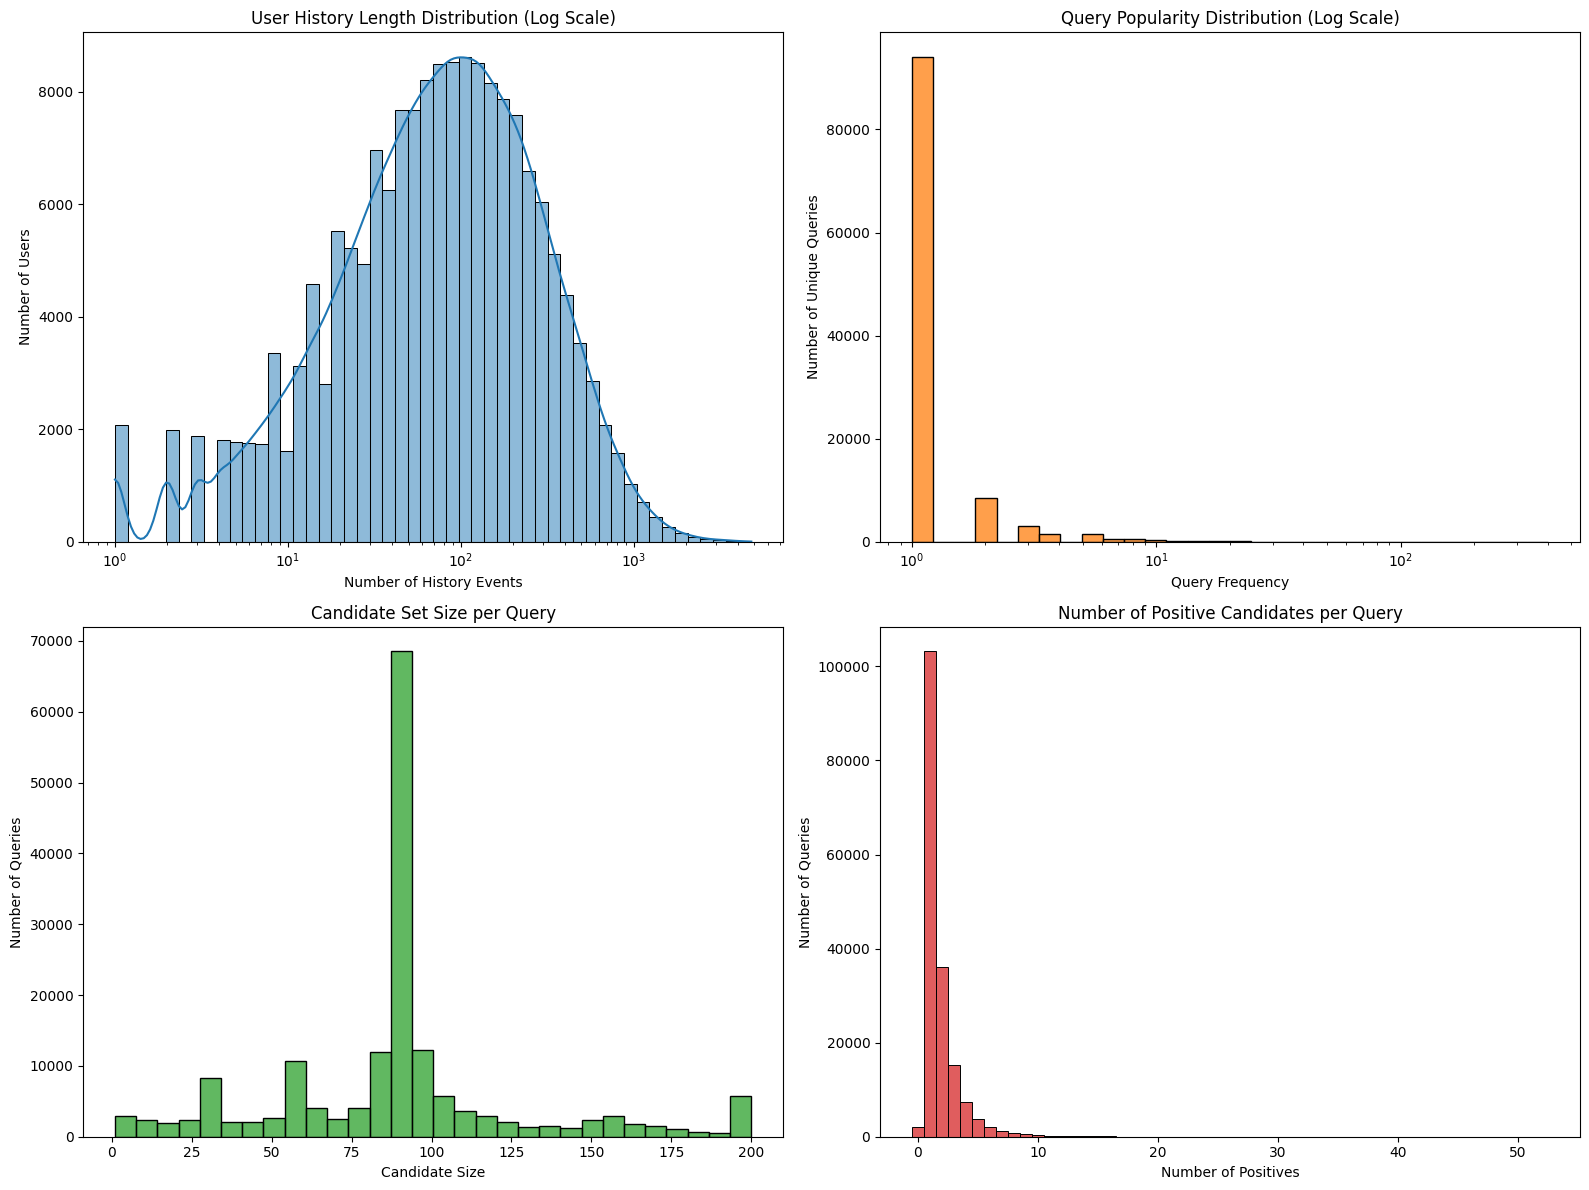

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (a) History length per user (log scale)
sns.histplot(tests['n_hist'], bins=50, log_scale=True, ax=axes[0, 0], color='#1f77b4', kde=True)
axes[0, 0].set_title('User History Length Distribution (Log Scale)')
axes[0, 0].set_xlabel('Number of History Events')
axes[0, 0].set_ylabel('Number of Users')

# (b) Queries per user
# Each user represents a unique test query, but we can verify unique text query frequencies
query_counts = tests['query'].value_counts()
sns.histplot(query_counts, bins=30, log_scale=True, ax=axes[0, 1], color='#ff7f0e', kde=False)
axes[0, 1].set_title('Query Popularity Distribution (Log Scale)')
axes[0, 1].set_xlabel('Query Frequency')
axes[0, 1].set_ylabel('Number of Unique Queries')

# (c) Candidate-set size
sns.histplot(tests['n_cand'], bins=30, ax=axes[1, 0], color='#2ca02c', kde=False)
axes[1, 0].set_title('Candidate Set Size per Query')
axes[1, 0].set_xlabel('Candidate Size')
axes[1, 0].set_ylabel('Number of Queries')

# (d) Positives per query
sns.histplot(tests['n_pos'], bins=range(0, int(tests['n_pos'].max()) + 2), ax=axes[1, 1], color='#d62728', kde=False, discrete=True)
axes[1, 1].set_title('Number of Positive Candidates per Query')
axes[1, 1].set_xlabel('Number of Positives')
axes[1, 1].set_ylabel('Number of Queries')

plt.tight_layout()
plt.savefig(f'{FIG}/a3_basic_user_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure A3.1 summary.**
- **(a) History length:** roughly bell-shaped on a log axis, centred near 100 events (median 78, 90th percentile 376, 99th 1,055, maximum 4,802). About 2,000 users each have exactly 1, 2 or 3 events: these are short-history users rather than users with no history. The heavy right tail is why history needs caps.
- **(b) Query popularity:** x is the number of users who issued the same test query, y the number of distinct queries. About 94,000 queries are issued by exactly one user and a few by hundreds, so about half of users have a query nobody else has. Query matching must therefore work on terms (TF-IDF), not on whole-query identity.
- **(c) Candidate-set size:** capped at 200, with a sharp peak at about 90 (roughly 68,000 queries, 39%) and a mean of 89. Smaller spikes sit near 30, 55–60 and 200. Queries with 10 or fewer candidates exist, where top-10 includes the whole list. Hit@10 is then 1 for retained queries, while NDCG@10 still depends on the ordering. Metrics should therefore be checked by candidate-set size.
- **(d) Positives per query:** about 103,000 queries (59%) have exactly 1 positive, about 36,000 have 2, and about 15,000 have 3, with a tail up to about 50. About 2,100 queries (1.2%) have none and are excluded from the metrics. With only 1–2 relevant items among about 90 candidates, per-query NDCG@10 and MRR are noisy. With exactly one positive among 90 candidates, random Hit@10 would be about 11% (10/90). Actual list sizes and positive counts vary; the random ranking evaluated in ModelComparison.ipynb reaches about 23% Hit@10 on test.

### 3. Analyze and Plot product popularity (long-tail), brand, and category cardinalities

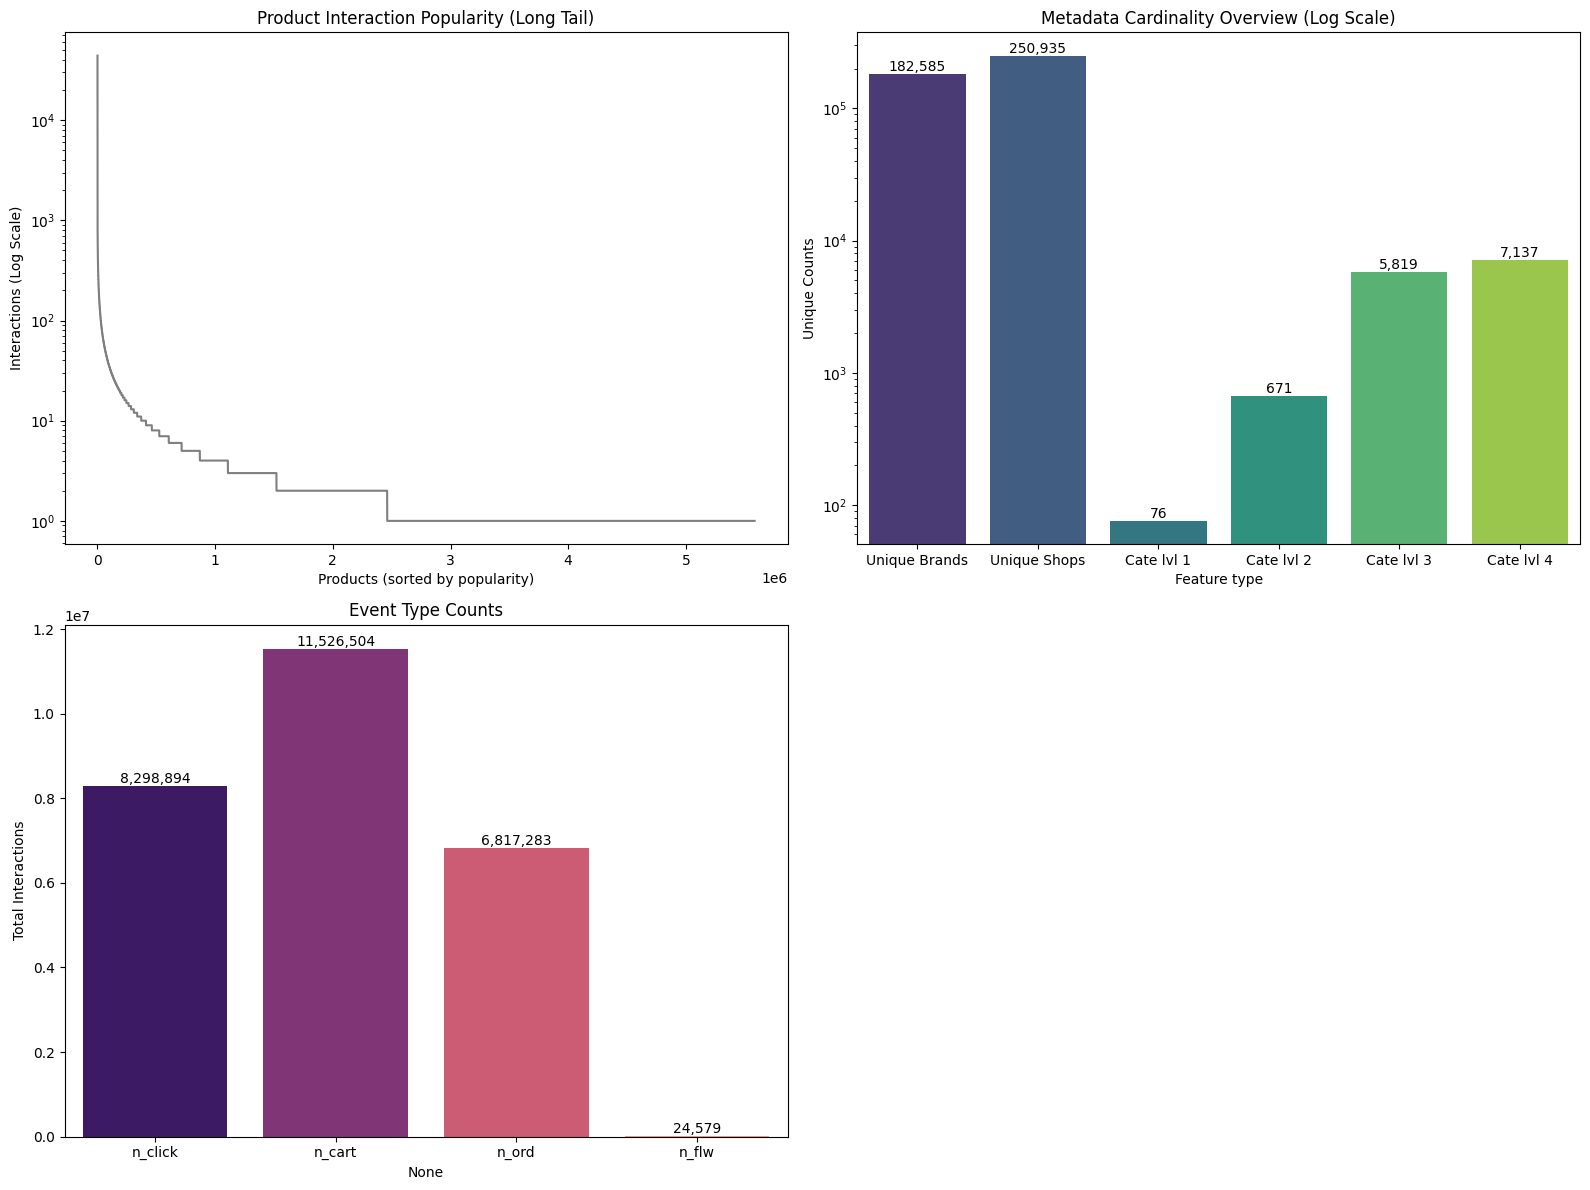

In [ ]:
# Read the unique product interaction frequencies from events
events_wid = pq.read_table(f'{LOCAL}/events.parquet', columns=['wid']).column('wid').to_pandas()
prod_popularity = events_wid.value_counts()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# (a) Long-tail product popularity
sns.lineplot(x=np.arange(len(prod_popularity)), y=prod_popularity.values, ax=axes[0, 0], color='#7f7f7f')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Product Interaction Popularity (Long Tail)')
axes[0, 0].set_xlabel('Products (sorted by popularity)')
axes[0, 0].set_ylabel('Interactions (Log Scale)')

# (b) Cardinality check
cardinalities = {
    'Unique Brands': products['brand_id'].nunique(),
    'Unique Shops': products['shop_id'].nunique(),
    'Cate lvl 1': products['cate_id_1'].nunique(),
    'Cate lvl 2': products['cate_id_2'].nunique(),
    'Cate lvl 3': products['cate_id_3'].nunique(),
    'Cate lvl 4': products['cate_id_4'].nunique()
}

card_df = pd.Series(cardinalities).reset_index()
card_df.columns = ['Entity', 'Count']

sns.barplot(data=card_df, x='Entity', y='Count', ax=axes[0, 1], palette='viridis', hue='Entity', legend=False)
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Metadata Cardinality Overview (Log Scale)')
axes[0, 1].set_ylabel('Unique Counts')
axes[0, 1].set_xlabel('Feature type')
for index, row in card_df.iterrows():
    axes[0, 1].text(index, row['Count'], f"{row['Count']:,}", color='black', ha="center", va="bottom")

# (c) Event type counts across entire dataset
tot_events = tests[['n_click', 'n_cart', 'n_ord', 'n_flw']].sum()
sns.barplot(x=tot_events.index, y=tot_events.values, ax=axes[1, 0], palette='magma', hue=tot_events.index, legend=False)
axes[1, 0].set_title('Event Type Counts')
axes[1, 0].set_ylabel('Total Interactions')
for index, val in enumerate(tot_events.values):
    axes[1, 0].text(index, val, f"{val:,}", color='black', ha="center", va="bottom")

# Remove unused empty subplot
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.savefig(f'{FIG}/a3_product_and_metadata_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

del events_wid

**Figure A3.2 summary.**
- **(a) Product popularity:** about 5.6M distinct product IDs appear in at least one history; some have no metadata. The top product has about 45,000 interactions, but roughly 56% of the products that appear have exactly one and about 73% have at most two. Most candidates are tail products, so popularity and CF features will be sparse or zero for them and `cf_coverage` matters. These counts use all users and must be recomputed on training users only.
- **(b) Metadata cardinality:** 182,585 brands, 250,935 shops, and 76 / 671 / 5,819 / 7,137 categories at levels 1–4. Brand and shop are high-cardinality, so use share and frequency features or embeddings, not one-hot encoding. Category level 1 is dense enough for shares, while level 4 is the narrow category. The brand count includes three placeholder ids that mean "no brand" (see the data-quality summary), so there are about 182,582 real brands.
- **(c) Event types:** 8.30M clicks, 11.53M carts, 6.82M orders and 24.6K follows (31%, 43%, 26% and 0.09%). Carts outnumbering clicks reflects the logging windows found in A4 (clicks are only recorded for about 7 days), not shopper behaviour. Follows are negligible.

# JDsearch – Step A4: running the temporal trace

**Question:** how do click, cart, order and follow events distribute over time before the test query, and is event type confounded with recency?

**Method:** every event carries `secs_before_q` (seconds before the test query). We turn it into days, then compare the mix of event types by days-before-query. Only the training users are used, so nothing here leaks validation or test users.

**Outputs:** figures and `trace_summary.json` in `Data/Figures`, and three lookback windows (A: 0–7, B: 7–90, C: 90–365 days) that the feature engineering will use.

## 1. Load training events and sanity-check
Loads the training split only (copied from Drive if missing). Checks that times are positive and ordered oldest to newest within each user.

In [ ]:
import os, shutil, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow.parquet as pq
try: from IPython.display import display
except ImportError: display = print

try:                                                       # Colab
    from google.colab import drive
    drive.mount('/content/drive')
    BASE, LOCAL = '/content/drive/MyDrive/bt4222_project', '/content/jd_local'
except ImportError:                                        # outside Colab (testing)
    BASE, LOCAL = os.environ['JD_BASE'], os.environ['JD_LOCAL']
OUT, FIG = f'{BASE}/Data/Processed', f'{BASE}/Data/Figures'
for d in (LOCAL, FIG): os.makedirs(d, exist_ok=True)
for n in ('events_train', 'tests_train'):
    if not os.path.exists(f'{LOCAL}/{n}.parquet'): shutil.copyfile(f'{OUT}/{n}.parquet', f'{LOCAL}/{n}.parquet')

ev = pq.read_table(f'{LOCAL}/events_train.parquet', columns=['user_id', 'etype', 'qless', 'secs_before_q']).to_pandas()
tr = pq.read_table(f'{LOCAL}/tests_train.parquet', columns=['user_id', 'n_hist']).to_pandas()
sec, et, ql, uid = ev.secs_before_q.to_numpy(), ev.etype.to_numpy(), ev.qless.to_numpy(), ev.user_id.to_numpy()

TYPES = {1: 'click', 2: 'cart', 3: 'order', 4: 'follow'}
COL = {1: '#1f77b4', 2: '#ff7f0e', 3: '#2ca02c', 4: '#7f7f7f'}

print(f'{len(ev):,} training events | {ev.user_id.nunique():,} users with history | {len(tr):,} training users')
print(f'min secs_before_q: {sec.min()} | max: {sec.max()/86400:.1f} days')
d = ev.groupby('user_id').secs_before_q.diff().dropna()
print(f'consecutive events ordered oldest -> newest: {(d <= 0).mean():.4%}')
del d

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
18,756,855 training events | 121,681 users with history | 121,681 training users
min secs_before_q: 1 | max: 365.0 days
consecutive events ordered oldest -> newest: 100.0000%


## 2. Build the daily count matrix
Every later result comes from one small matrix: events per event type (rows) per day before the query (columns). Day 0 is the last 24 hours before the test query. `W_CLICK` and `W_CART` are the lookbacks read from the first full run (checked in section 4).

In [ ]:
day = (sec // 86400).astype(np.int32)
D = int(day.max()) + 1                                     # number of day columns
W_CLICK, W_CART = 7, 90                                    # click and cart/follow lookback in days; orders cover all D days

def daily_counts(mask=None):
    m = np.ones(len(day), bool) if mask is None else mask
    return np.stack([np.bincount(day[m & (et == k)], minlength=D) for k in TYPES])   # shape (4, D)

def to_bins(mat, edges):                                    # sum day columns into bins [edges[i], edges[i+1])
    return np.stack([mat[:, a:b].sum(1) for a, b in zip(edges[:-1], edges[1:])], axis=1)

def save(name): plt.savefig(f'{FIG}/a4_{name}.png', dpi=150, bbox_inches='tight')

daily = daily_counts()
assert daily.sum() == len(ev)
tot = daily.sum(1)
print(pd.DataFrame({'events': tot, 'share': (tot / tot.sum()).round(4)}, index=list(TYPES.values())))

         events   share
click   5832871  0.3110
cart    8116301  0.4327
order   4790090  0.2554
follow    17593  0.0009


## 3. Event mix over time
Left: share of each event type per bin of days before the query. Right: events per day (log scale; divided by bin width so wide bins do not look busier). Dashed lines mark the two window boundaries, 7 and 90 days.

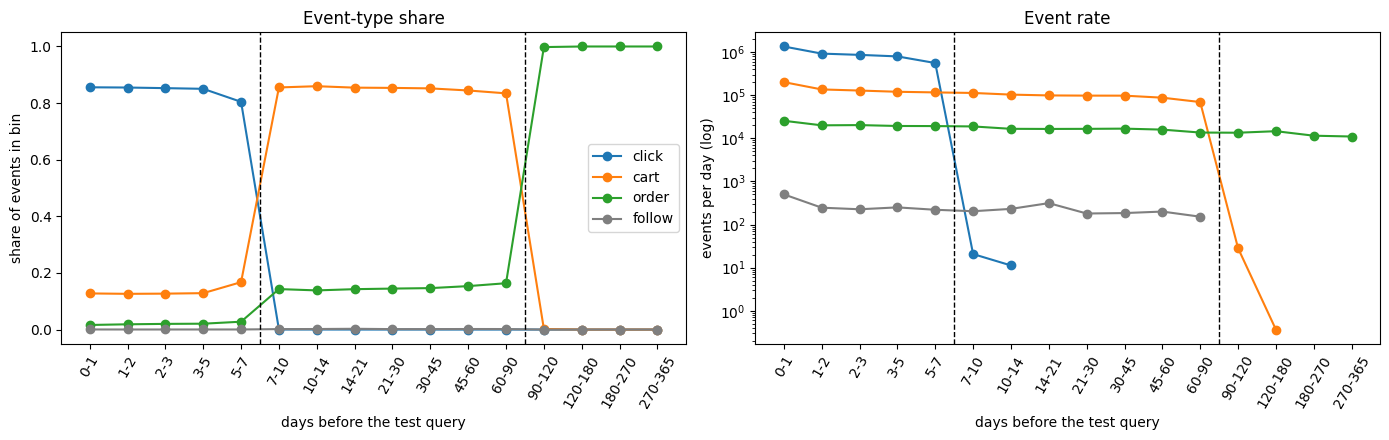

,click,cart,order,follow
0-1,0.856,0.128,0.016,0.000
1-2,0.855,0.126,0.019,0.000
2-3,0.853,0.127,0.020,0.000
3-5,0.850,0.129,0.021,0.000
5-7,0.804,0.167,0.028,0.000
7-10,0.000,0.855,0.143,0.002
10-14,0.000,0.860,0.138,0.002
14-21,0.000,0.855,0.143,0.003
21-30,0.000,0.854,0.145,0.002
30-45,0.000,0.852,0.146,0.002


In [ ]:
LOG_EDGES = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60, 90, 120, 180, 270, 365]
edges = [e for e in LOG_EDGES if e < D] + [D]
labels = [f'{a}-{b}' for a, b in zip(edges[:-1], edges[1:])]
widths = np.diff(edges)
lb = to_bins(daily, edges)
bounds = [edges.index(w) - .5 for w in (W_CLICK, W_CART) if w in edges]     # x position of the window boundaries
share_tab = pd.DataFrame(lb / np.maximum(lb.sum(0, keepdims=True), 1), index=list(TYPES.values()), columns=labels).T

def style(a, xs):
    a.set_xticks(xs); a.set_xticklabels(labels, rotation=60); a.set_xlabel('days before the test query')
    for b in bounds: a.axvline(b, color='k', ls='--', lw=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5)); xs = np.arange(len(labels))
for i, k in enumerate(TYPES):
    ax[0].plot(xs, share_tab[TYPES[k]], marker='o', color=COL[k], label=TYPES[k])
    ax[1].plot(xs, np.where(lb[i] > 0, lb[i] / widths, np.nan), marker='o', color=COL[k], label=TYPES[k])
for a in ax: style(a, xs)
ax[0].set(ylabel='share of events in bin', title='Event-type share'); ax[1].set(yscale='log', ylabel='events per day (log)', title='Event rate')
ax[0].legend(); plt.tight_layout(); save('fig1_mix_over_time'); plt.show()
display(share_tab.round(3))

**Figure 1 summary.** The mix is a staircase. Up to day 7, about 85% of events are clicks (about 13% carts, 2% orders). From day 7 to day 90 there are almost no clicks: about 85% carts and 14–16% orders. After day 90 almost every event is an order. The rate panel shows why: clicks run at roughly a million per day in the last days and fall to almost nothing after day 7, carts drop off after day 90, while orders stay flat across the whole year. Event type and recency are therefore strongly confounded: each type is only recorded for a limited lookback.

## 4. Lookback per event type
For each type: where its events sit in time (median, 90th and 99th percentile of days-before-query, last day with any event) and how much falls in the last 7, 30 and 90 days. `beyond_own_window` checks the chosen lookbacks: the share of a type's events older than 7 days for clicks, older than 90 days for carts and follows, and over the full range for orders.

In [ ]:
def day_q(row, q):  c = np.cumsum(row); return int(np.searchsorted(c, q * max(c[-1], 1)))
def within(row, n): c = np.cumsum(row); return c[min(n, D) - 1] / max(c[-1], 1)

OWN = {1: W_CLICK, 2: W_CART, 3: D, 4: W_CART}               # lookback of each event type
hz = pd.DataFrame([dict(type=TYPES[k], events=int(r.sum()), p50=day_q(r, .5), p90=day_q(r, .9), p99=day_q(r, .99),
                        max_day=int(np.nonzero(r)[0].max()), within_7d=within(r, 7), within_30d=within(r, 30),
                        within_90d=within(r, 90), beyond_own_window=1 - within(r, OWN[k]))
                   for k, r in zip(TYPES, daily)]).set_index('type')
display(hz.round(5))

,events,p50,p90,p99,max_day,within_7d,within_30d,within_90d,beyond_own_window
type,,,,,,,,,
click,5832871,2,5,6,13,0.99998,1.00000,1.00000,0.00002
cart,8116301,38,78,88,157,0.11547,0.40153,0.99989,0.00011
order,4790090,154,320,359,364,0.02981,0.11070,0.29819,0.00000
follow,17593,39,76,87,89,0.10874,0.41295,1.00000,0.00000


**Summary.** Clicks: median day 2, 99th percentile day 6, and only 0.002% of clicks are older than 7 days. Carts and follows: median about day 38, 99th percentile about day 88, so a 90-day lookback. Carts older than 90 days are a negligible tail (the maximum is day 157). Orders: median day 154, 99th percentile day 359, so the full year. These three lookbacks (7, 90 and 365 days) define the windows used below.

## 5. Query-less vs query-linked events
Query-less events were not made under a search (e.g. browsing or recommendations). The table shows how many events of each type are query-less, and the percentiles per group. The figure repeats the event-rate panel of Figure 1 for each group. If the windows are the same for both, they are a property of the event type, not of how the event came about.

,share query-less
click,0.717
cart,0.690
order,0.490
follow,0.996


events            p50         p99      
query_less    False    True  False True  False True 
type                                                
click       1652398  4180473     2     2     6     6
cart        2519982  5596319    38    38    88    88
order       2441666  2348424   153   155   359   359
follow           76    17517    34    39    89    87

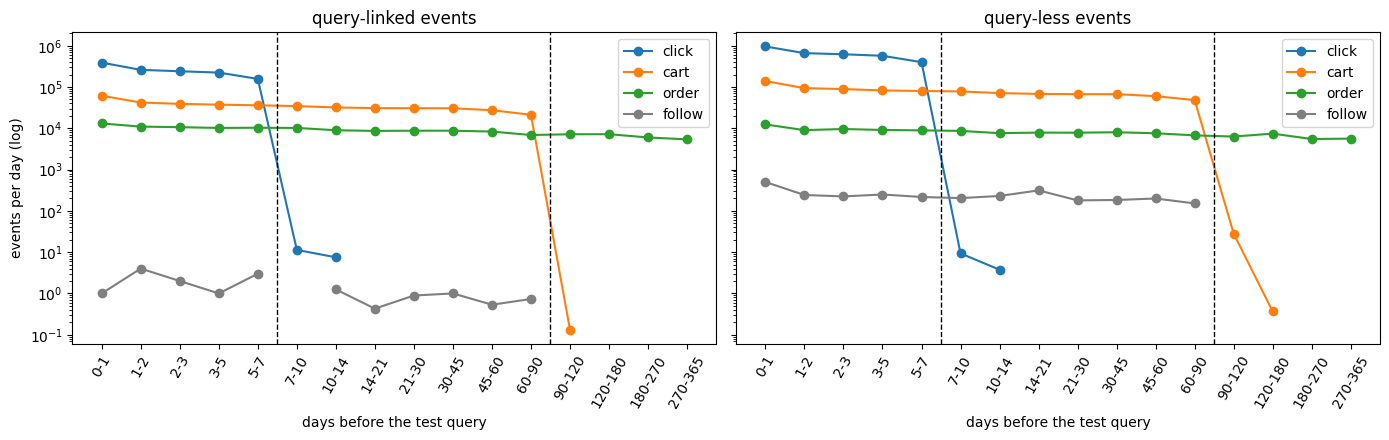

In [ ]:
dq = {False: daily_counts(~ql), True: daily_counts(ql)}
display(pd.Series({TYPES[k]: ql[et == k].mean() for k in TYPES}, name='share query-less').round(3).to_frame())
rows = [dict(type=TYPES[k], query_less=q, events=int(r.sum()), p50=day_q(r, .5), p99=day_q(r, .99))
        for q in (False, True) for k, r in zip(TYPES, dq[q]) if r.sum() > 0]
display(pd.DataFrame(rows).pivot(index='type', columns='query_less', values=['events', 'p50', 'p99']).reindex(list(TYPES.values())))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, q, t in zip(ax, (False, True), ('query-linked events', 'query-less events')):
    b = to_bins(dq[q], edges)
    for i, k in enumerate(TYPES): a.plot(xs, np.where(b[i] > 0, b[i] / widths, np.nan), marker='o', color=COL[k], label=TYPES[k])
    style(a, xs); a.set(yscale='log', title=t); a.legend()
ax[0].set_ylabel('events per day (log)'); plt.tight_layout(); save('fig2_query_less'); plt.show()

**Figure 2 summary.** Query-less events are the majority: about 72% of clicks, 69% of carts, 49% of orders and 99.6% of follows. Both panels show the same staircase with the same cut-offs (clicks gone after about a week, carts after about 90 days, orders across the year), and the percentiles agree to within a day. The windows therefore do not depend on whether a search was involved. The query-less flag is retained to select the approximately 35% of events that are search-linked for past-query similarity; it is not a separate Model B input. Query-linked follows are practically absent (76 events).

## 6. User-level coverage and robustness
First, how many users have each event type at all. Then (a) the click share by log bin within history-length quartiles, to check the pattern is not driven by long-history users, and (b) the share of users with at least one event of each type per bin, which heavy users cannot dominate.

users with >=1 click                  0.838
users with >=1 cart                   0.957
users with >=1 order                  0.916
users with >=1 follow                 0.012
users with cart/order but no click    0.162
median oldest click: 5.0 days | median oldest cart/order: 305.9 days


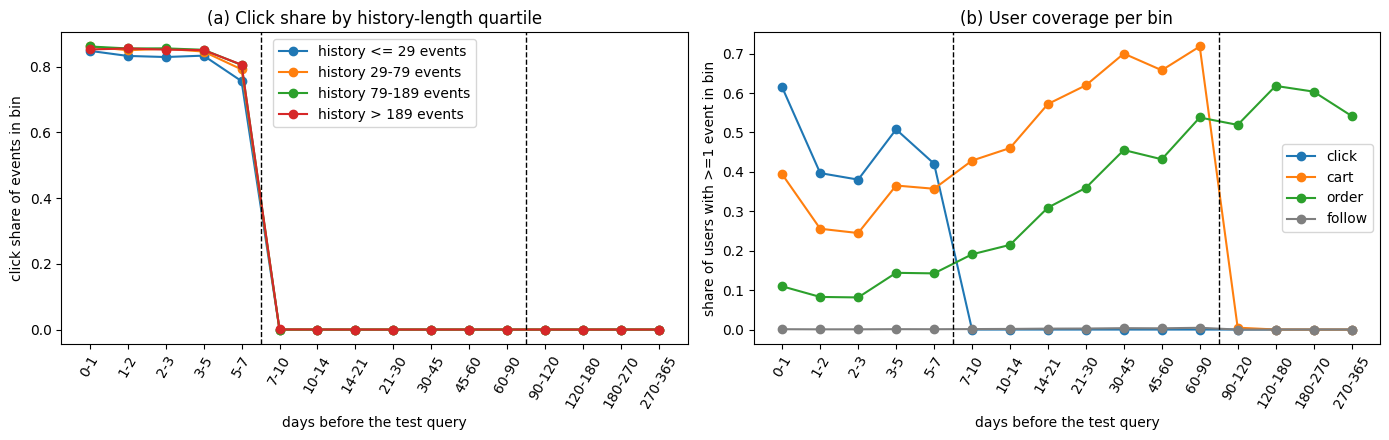

In [ ]:
old = pd.DataFrame({TYPES[k]: pd.DataFrame({'u': uid[et == k], 'd': sec[et == k] / 86400}).groupby('u').d.max() for k in TYPES})
n_users = ev.user_id.nunique(); has = old.notna()
per_user = {f'users with >=1 {TYPES[k]}': has[TYPES[k]].mean() for k in TYPES}
per_user['users with cart/order but no click'] = (~has.click & (has.cart | has.order)).mean()
print(pd.Series(per_user).round(3).to_string())
both = old.dropna(subset=['click']).assign(deep=old[['cart', 'order']].max(axis=1)).dropna(subset=['deep'])
print(f'median oldest click: {both.click.median():.1f} days | median oldest cart/order: {both.deep.median():.1f} days')

qe = tr.n_hist[tr.n_hist > 0].quantile([.25, .5, .75]).to_numpy()
nh = np.zeros(int(tr.user_id.max()) + 1, np.int64); nh[tr.user_id.to_numpy()] = tr.n_hist.to_numpy()
strat = np.digitize(nh[uid], qe)                           # 0..3 = history-length quartile
cnt = np.bincount((strat * 5 + et) * D + day, minlength=4 * 5 * D).reshape(4, 5, D)[:, 1:, :]
names = [f'<= {qe[0]:.0f}'] + [f'{qe[i]:.0f}-{qe[i+1]:.0f}' for i in range(2)] + [f'> {qe[2]:.0f}']

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for s in range(4):
    b = to_bins(cnt[s], edges); ax[0].plot(xs, b[0] / np.maximum(b.sum(0), 1), marker='o', label=f'history {names[s]} events')
ax[0].set(ylabel='click share of events in bin', title='(a) Click share by history-length quartile')
bin_of = np.digitize(day, edges[1:-1])                      # log-bin index per event
for k in TYPES:
    m = et == k; pairs = np.unique(uid[m].astype(np.int64) * len(labels) + bin_of[m])
    ax[1].plot(xs, np.bincount(pairs % len(labels), minlength=len(labels)) / n_users, marker='o', color=COL[k], label=TYPES[k])
ax[1].set(ylabel='share of users with >=1 event in bin', title='(b) User coverage per bin'); ax[1].legend()
for a in ax: style(a, xs)
ax[0].legend(); plt.tight_layout(); save('fig3_user_level'); plt.show()

**Figure 3 summary.** User level: 83.8% of users have at least one click, 95.7% a cart, 91.6% an order and only 1.2% a follow. 16.2% of users have carts or orders but no click at all. The median user's oldest click is 5 days back, against about 306 days for the oldest cart or order. (a) The click share curves of the four history-length quartiles lie on top of each other: about 85% until day 7, then approximately 0. The window is therefore not an artifact of heavy users. (b) The share of users with a click per bin drops to almost 0 after day 7, and the share with a cart drops to almost 0 after day 90, for essentially all users. Orders stay present in every bin out to the end of the year.

## 7. The three windows: composition and per-user volume
Window A = days 0–7 (clicks, carts and orders are all recorded), B = days 7–90 (predominantly carts and orders), C = days 90–365 (almost entirely orders). First, how many events of each type fall in each window. Second, how many users have events of each type per window and how many events they have (median, 90th and 99th percentile among users with at least one), which can inform history caps in possible model extensions. The results are saved to `trace_summary.json`.

In [ ]:
WIN_EDGES = [0, W_CLICK, W_CART, D]
WIN_NAMES = [f'A: 0-{W_CLICK}d', f'B: {W_CLICK}-{W_CART}d', f'C: {W_CART}-{D}d']
win = np.digitize(day, WIN_EDGES[1:-1])                    # 0 = A, 1 = B, 2 = C
comp = pd.DataFrame(to_bins(daily, WIN_EDGES).T, index=WIN_NAMES, columns=list(TYPES.values()))
display(comp.assign(total=comp.sum(1), share_of_all=(comp.sum(1) / comp.values.sum()).round(3)))
display((comp.div(comp.sum(1), axis=0)).round(3).rename_axis('type share per window'))

key = (uid.astype(np.int64) * 3 + win) * 5 + et            # user x window x type
cnt_u = np.bincount(key, minlength=(int(uid.max()) + 1) * 15).reshape(-1, 3, 5)[:, :, 1:]
vol = []
for w, wn in enumerate(WIN_NAMES):
    for i, k in enumerate(TYPES):
        c = cnt_u[:, w, i]; c = c[c > 0]
        if len(c) >= 100: vol.append(dict(window=wn, type=TYPES[k], users_with_event=len(c) / n_users,
                                          median=np.median(c), p90=np.percentile(c, 90), p99=np.percentile(c, 99)))
vol = pd.DataFrame(vol).set_index(['window', 'type'])
display(vol.round(3))

summary = dict(
    n_train_events=int(len(ev)), n_train_users_with_history=int(n_users), days_span=int(D),
    windows={'click_days': W_CLICK, 'cart_follow_days': W_CART, 'order_days': int(D)},
    event_share={TYPES[k]: float(tot[i] / tot.sum()) for i, k in enumerate(TYPES)},
    horizon_days=hz[['p50', 'p90', 'p99', 'max_day']].to_dict('index'),
    beyond_own_window=hz.beyond_own_window.to_dict(),
    window_composition=comp.to_dict('index'),
    per_user_volume={f'{a}|{b}': r for (a, b), r in vol.to_dict('index').items()},
    user_level={k: float(v) for k, v in per_user.items()})
json.dump(summary, open(f'{FIG}/trace_summary.json', 'w'), indent=2, default=float)
print('saved', f'{FIG}/trace_summary.json')

,click,cart,order,follow,total,share_of_all
A: 0-7d,5832764,937219,142816,1913,6914712,0.369
B: 7-90d,107,7178211,1285540,15680,8479538,0.452
C: 90-365d,0,871,3361734,0,3362605,0.179


,click,cart,order,follow
type share per window,,,,
A: 0-7d,0.844,0.136,0.021,0.000
B: 7-90d,0.000,0.847,0.152,0.002
C: 90-365d,0.000,0.000,1.000,0.000


users_with_event  median    p90     p99
window     type                                           
A: 0-7d    click              0.838    25.0  140.0  457.00
           cart               0.712     5.0   26.0   80.00
           order              0.374     2.0    7.0   18.00
           follow             0.003     2.0   12.7   58.38
B: 7-90d   cart               0.920    29.0  158.0  489.00
           order              0.781     7.0   33.0   96.00
           follow             0.011     3.0   25.0  146.89
C: 90-365d cart               0.005     1.0    3.0    5.00
           order              0.781    15.0   90.0  269.00

saved /content/drive/MyDrive/bt4222_project/Data/Figures/trace_summary.json


**Summary.** The three windows hold 6.9M events (36.9%, window A), 8.5M (45.2%, window B) and 3.4M (17.9%, window C, almost entirely orders). Window A is 84% clicks, window B is 85% carts and 15% orders. Clicks occur almost entirely in A, carts almost entirely in A and B, and orders in all three windows (stray events outside a type's lookback number only 107 clicks in B and 871 carts in C). Per user, among those who have the event type: clicks in A have a median of 25 and a 90th percentile of 140 (84% of users); carts in B have 29 and 158 (92% of users); orders in C have 15 and 90 (78% of users). Orders in B and in A have lower volumes (medians 7 and 2), and follows are negligible in every window (at most 1.1% of users). These percentiles can guide history caps in possible model extensions.

## Conclusion: how the temporal trace informs our features

**Finding.** The event types have different observed logging horizons: approximately 7 days for clicks, 90 days for carts and follows, and 365 days for orders. Older missing clicks therefore generally reflect the recording horizon rather than an absence of interest. Overall event counts across types are not directly comparable.

| Window | Days before query | Predominant recorded event types | Interpretation |
|---|---|---|---|
| A | 0–7 | click, cart, order | recent activity |
| B | 7–90 | cart, order | medium-term history |
| C | 90–365 | order | longer-term purchase history |

**How this is used in the final pipeline**
1. **Separate behavior types.** History counts, same-product counts, and category and brand shares distinguish orders, carts and clicks. Rare events outside the typical logging horizons are retained.
2. **Affinity and recency.** Category shares and recencies are computed per event type. Brand shares are also per type; brand recency and shop share use orders. `prev_days_since` measures the most recent interaction with the exact candidate across the retained event types.
3. **Missing values differ from zeros.** Counts are 0 when no matching event exists. Shares are NaN when the shopper has no events of that type or the candidate attribute is unknown. Recency is NaN when no matching event exists.
4. **Collaborative filtering.** The final implementation uses one weighted product-by-shopper matrix (order 3, cart 2, click 1, then `log1p`) reduced by truncated SVD. Training users are scored with out-of-fold books; validation and test users use a book fitted on all training users.
5. **Past-query similarity.** Only query-linked history events are used. Recency decay uses half-lives of 2, 38 and 154 days for clicks, carts and orders, respectively.
6. **History availability.** Follow events are excluded from Model B's history features. Every user has at least one recorded event, so `has_history` is not used. History size is represented by the log-transformed order, cart and click counts.
7. **Evaluation.** ModelComparison.ipynb examines gains by history amount, click availability and other segments. Feature-group knockout is performed. Retrained ablations are available as an optional step but were not run.

**Possible extensions, not implemented.** Separate CF matrices per event type, additional window-specific features, a neural history model and a stacker were considered during planning. They are not part of the final pipeline.

**Formulation.** Historical events are model inputs. The final-query candidate label is a separate observed outcome: 0 for no interaction, 1 for click, 2 for cart and 3 for purchase. History weights and decay settings describe the input representation; they do not define the target labels.